In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

Saving india_job_market_2024_2026.csv to india_job_market_2024_2026.csv


In [ ]:
print("First five records:")
display(df.head())

First five records:


,Job_ID,Job_Title,Company,Company_Type,Industry,City,Location_Tier,Experience_Level,Job_Type,Work_Mode,Salary_LPA,Skills_Required,Education_Required,Openings,Applicants,Company_Rating,Date_Posted,Experience_Years
0,IND2025000,Android Developer,Tech Mahindra,MNC,Information Technology,Remote,Remote,Senior (6-10 yrs),Full-Time,Remote,30.9,"Kotlin, Java, REST APIs",M.Tech/M.E.,3,276,4.0,2025-10-31,8.0
1,IND2025001,QA Engineer,Dream11,Indian Unicorn,Information Technology,Lucknow,Tier 2,Senior (6-10 yrs),Full-Time,Hybrid,58.6,"Selenium, Manual Testing, Postman, API Testing...",B.Tech/B.E.,3,325,4.0,2025-05-19,8.0
2,IND2025002,Business Analyst,HAL,PSU/Govt,EdTech,Remote,Remote,Senior (6-10 yrs),Full-Time,Remote,18.4,"JIRA, Excel, Power BI",MCA,5,559,3.6,2024-08-21,8.0
3,IND2025003,Cybersecurity Analyst,Groww,Startup,Information Technology,Mumbai,Tier 1,Mid (3-6 yrs),Full-Time,Hybrid,21.7,"Penetration Testing, Python, Ethical Hacking, ...",BCA,3,184,3.5,2026-03-18,4.5
4,IND2025004,Python Developer,Oracle,MNC,EdTech,Remote,Remote,Junior (1-3 yrs),Full-Time,Remote,8.0,"Docker, REST APIs, AWS, PostgreSQL",MCA,1,64,3.9,2024-10-25,2.0


In [ ]:
print("Rows and columns:", df.shape)

print("\nDataset information:")
df.info()

Rows and columns: (5000, 18)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Job_ID              5000 non-null   object        
 1   Job_Title           5000 non-null   object        
 2   Company             5000 non-null   object        
 3   Company_Type        5000 non-null   object        
 4   Industry            5000 non-null   object        
 5   City                5000 non-null   object        
 6   Location_Tier       5000 non-null   object        
 7   Experience_Level    5000 non-null   object        
 8   Job_Type            5000 non-null   object        
 9   Work_Mode           5000 non-null   object        
 10  Salary_LPA          5000 non-null   float64       
 11  Skills_Required     5000 non-null   object        
 12  Education_Required  5000 non-null   object        
 1

In [ ]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Job_ID', 'Job_Title', 'Company', 'Company_Type', 'Industry', 'City', 'Location_Tier', 'Experience_Level', 'Job_Type', 'Work_Mode', 'Salary_LPA', 'Skills_Required', 'Education_Required', 'Openings', 'Applicants', 'Company_Rating', 'Date_Posted', 'Experience_Years']


In [ ]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
Job_ID                0
Job_Title             0
Company               0
Company_Type          0
Industry              0
City                  0
Location_Tier         0
Experience_Level      0
Job_Type              0
Work_Mode             0
Salary_LPA            0
Skills_Required       0
Education_Required    0
Openings              0
Applicants            0
Company_Rating        0
Date_Posted           0
Experience_Years      0
dtype: int64

Duplicate Records: 0


In [ ]:
# Remove duplicates
df = df.drop_duplicates().copy()

In [ ]:
# Clean column names
df.columns = df.columns.str.strip()

In [ ]:
# Convert numerical columns
numeric_columns = [
    "Salary_LPA",
    "Openings",
    "Applicants",
    "Company_Rating"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")


In [ ]:
# Convert date column
df["Date_Posted"] = pd.to_datetime(
    df["Date_Posted"],
    format="%d-%m-%Y",
    errors="coerce"
)

In [ ]:
# Replace empty strings with missing values
df.replace(r"^\s*$", np.nan, regex=True, inplace=True)

# Remove rows without salary
df = df.dropna(subset=["Salary_LPA"]).copy()

In [ ]:
# Fill missing numerical values using median
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values
categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns

In [ ]:
for col in categorical_columns:
    df[col] = df[col].fillna("Unknown")

print("\nCleaned Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

display(df.head())


Cleaned Dataset Shape: (5000, 18)

Missing Values After Cleaning:
Job_ID                0
Job_Title             0
Company               0
Company_Type          0
Industry              0
City                  0
Location_Tier         0
Experience_Level      0
Job_Type              0
Work_Mode             0
Salary_LPA            0
Skills_Required       0
Education_Required    0
Openings              0
Applicants            0
Company_Rating        0
Date_Posted           0
Experience_Years      0
dtype: int64


,Job_ID,Job_Title,Company,Company_Type,Industry,City,Location_Tier,Experience_Level,Job_Type,Work_Mode,Salary_LPA,Skills_Required,Education_Required,Openings,Applicants,Company_Rating,Date_Posted,Experience_Years
0,IND2025000,Android Developer,Tech Mahindra,MNC,Information Technology,Remote,Remote,Senior (6-10 yrs),Full-Time,Remote,30.9,"Kotlin, Java, REST APIs",M.Tech/M.E.,3,276,4.0,2025-10-31,8.0
1,IND2025001,QA Engineer,Dream11,Indian Unicorn,Information Technology,Lucknow,Tier 2,Senior (6-10 yrs),Full-Time,Hybrid,58.6,"Selenium, Manual Testing, Postman, API Testing...",B.Tech/B.E.,3,325,4.0,2025-05-19,8.0
2,IND2025002,Business Analyst,HAL,PSU/Govt,EdTech,Remote,Remote,Senior (6-10 yrs),Full-Time,Remote,18.4,"JIRA, Excel, Power BI",MCA,5,559,3.6,2024-08-21,8.0
3,IND2025003,Cybersecurity Analyst,Groww,Startup,Information Technology,Mumbai,Tier 1,Mid (3-6 yrs),Full-Time,Hybrid,21.7,"Penetration Testing, Python, Ethical Hacking, ...",BCA,3,184,3.5,2026-03-18,4.5
4,IND2025004,Python Developer,Oracle,MNC,EdTech,Remote,Remote,Junior (1-3 yrs),Full-Time,Remote,8.0,"Docker, REST APIs, AWS, PostgreSQL",MCA,1,64,3.9,2024-10-25,2.0


In [ ]:
print("Salary Mean:", df["Salary_LPA"].mean())
print("Salary Median:", df["Salary_LPA"].median())
print("Salary Mode:", df["Salary_LPA"].mode().tolist())
print("Salary Variance:", df["Salary_LPA"].var())
print("Salary Standard Deviation:", df["Salary_LPA"].std())

print("\nSalary Quartiles:")
print(df["Salary_LPA"].quantile([0.25, 0.50, 0.75]))

print("\nComplete Descriptive Statistics:")
display(df.describe())

Salary Mean: 19.829439999999998
Salary Median: 13.6
Salary Mode: [6.2]
Salary Variance: 328.9413735611111
Salary Standard Deviation: 18.13674098511392

Salary Quartiles:
0.25     6.8
0.50    13.6
0.75    25.6
Name: Salary_LPA, dtype: float64

Complete Descriptive Statistics:


,Salary_LPA,Openings,Applicants,Company_Rating,Date_Posted,Experience_Years
count,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.00000
mean,19.829440,3.642600,302.072000,3.698420,2025-05-16 11:47:54.240000,4.20040
min,0.800000,1.000000,14.000000,2.500000,2024-06-01 00:00:00,0.50000
25%,6.800000,1.000000,99.000000,3.400000,2024-11-19 18:00:00,2.00000
50%,13.600000,2.000000,185.000000,3.800000,2025-05-16 00:00:00,4.50000
75%,25.600000,3.000000,321.000000,4.100000,2025-11-03 06:00:00,8.00000
max,115.400000,20.000000,2387.000000,4.300000,2026-04-30 00:00:00,10.00000
std,18.136741,4.046942,363.989613,0.424994,NaN,3.14519


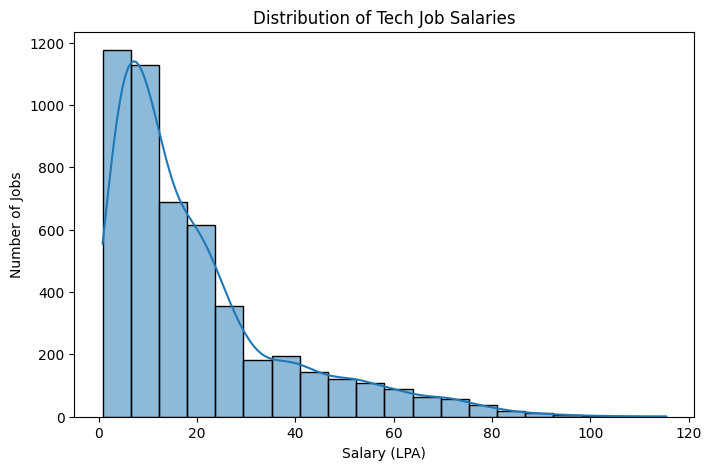

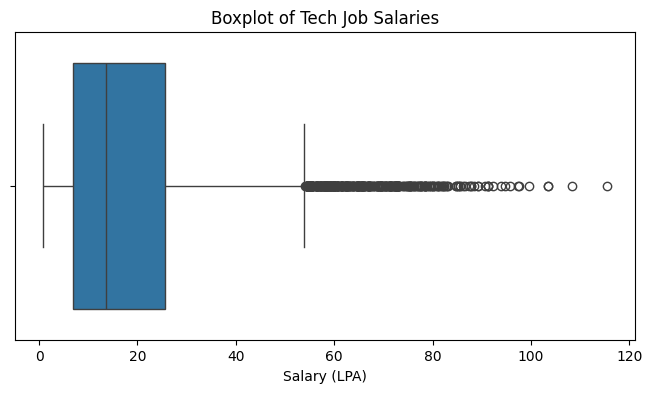

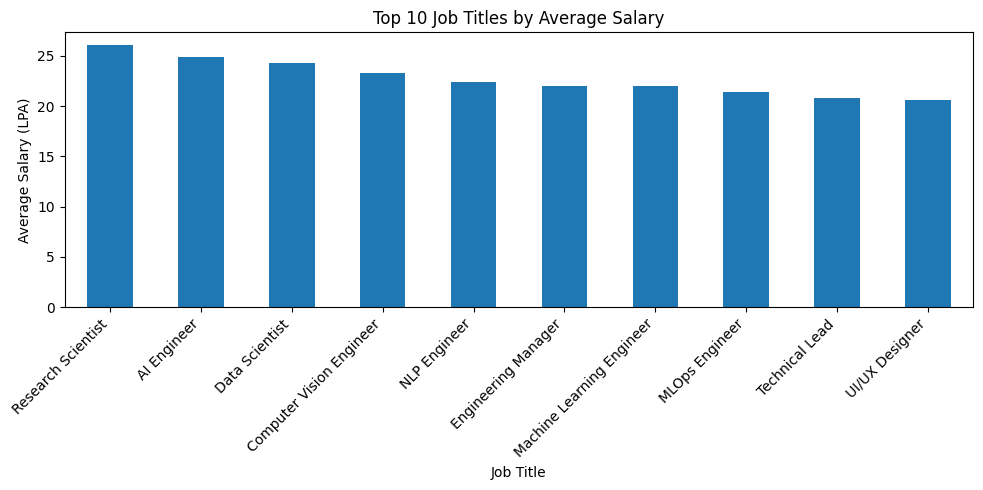

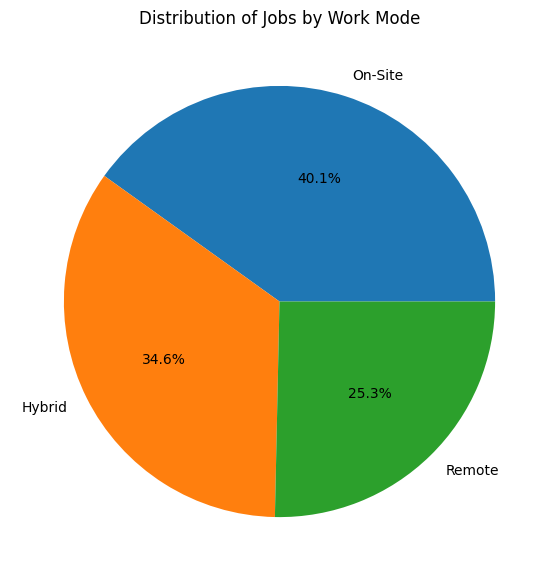

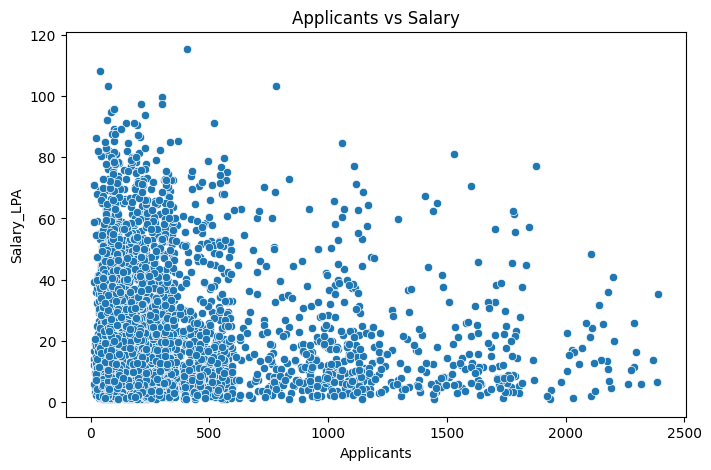

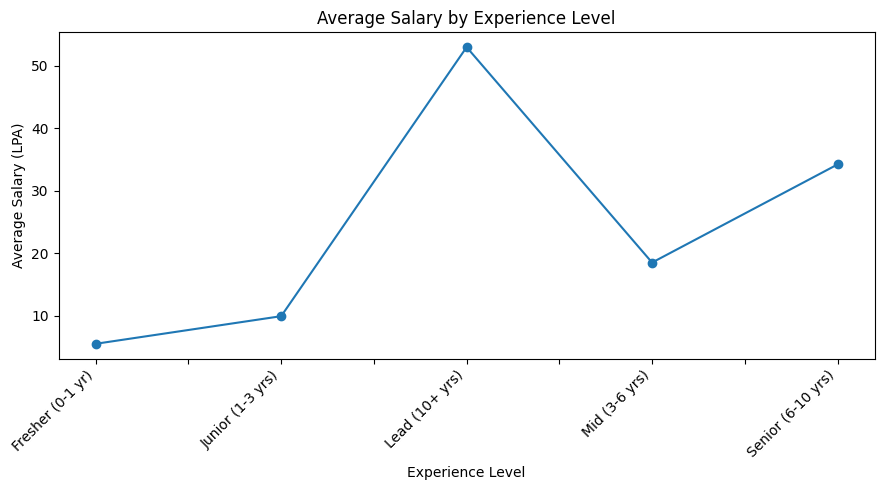

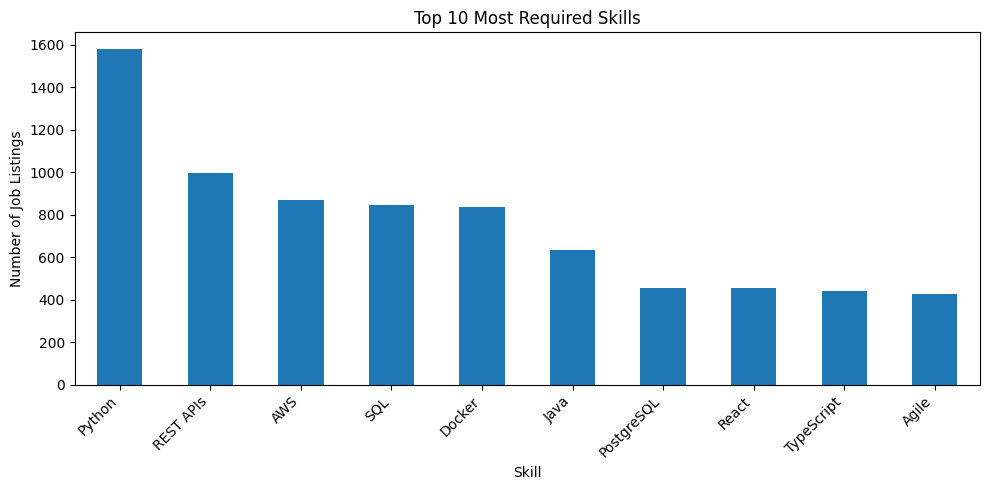

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Salary distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Salary_LPA"], bins=20, kde=True)
plt.title("Distribution of Tech Job Salaries")
plt.xlabel("Salary (LPA)")
plt.ylabel("Number of Jobs")
plt.show()

# 2. Salary outliers
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Salary_LPA"])
plt.title("Boxplot of Tech Job Salaries")
plt.xlabel("Salary (LPA)")
plt.show()

# 3. Average salary by job title (top 10)
top_jobs = (
    df.groupby("Job_Title")["Salary_LPA"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_jobs.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Job Titles by Average Salary")
plt.xlabel("Job Title")
plt.ylabel("Average Salary (LPA)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 4. Jobs by work mode
df["Work_Mode"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", figsize=(7, 7)
)
plt.title("Distribution of Jobs by Work Mode")
plt.ylabel("")
plt.show()

# 5. Applicants vs salary
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Applicants", y="Salary_LPA")
plt.title("Applicants vs Salary")
plt.show()

# 6. Average salary by experience level
experience_salary = df.groupby("Experience_Level")["Salary_LPA"].mean()

experience_salary.plot(kind="line", marker="o", figsize=(9, 5))
plt.title("Average Salary by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Average Salary (LPA)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 7. Most frequently required skills
skills = (
    df["Skills_Required"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

top_skills = skills[skills != ""].value_counts().head(10)

top_skills.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Most Required Skills")
plt.xlabel("Skill")
plt.ylabel("Number of Job Listings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Population Mean: 19.829439999999998
Mean of Sample Means: 19.87896
Standard Error of Sample Means: 3.3056896662021837


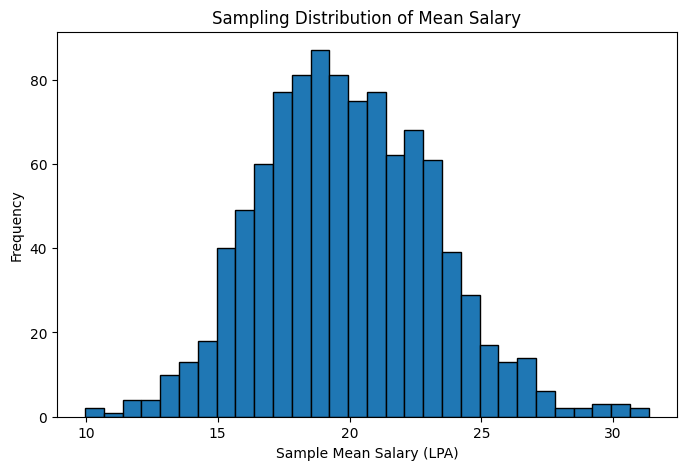

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

population = df["Salary_LPA"].dropna().to_numpy()

population_mean = np.mean(population)
sample_size = 30
number_of_samples = 1000

sample_means = []

for i in range(number_of_samples):
    sample = np.random.choice(
        population,
        size=sample_size,
        replace=True
    )
    sample_means.append(np.mean(sample))

print("Population Mean:", population_mean)
print("Mean of Sample Means:", np.mean(sample_means))
print("Standard Error of Sample Means:", np.std(sample_means, ddof=1))

plt.figure(figsize=(8, 5))
plt.hist(sample_means, bins=30, edgecolor="black")
plt.title("Sampling Distribution of Mean Salary")
plt.xlabel("Sample Mean Salary (LPA)")
plt.ylabel("Frequency")
plt.show()

In [ ]:
sample = df["Salary_LPA"].dropna().sample(
    n=min(30, df["Salary_LPA"].notna().sum()),
    random_state=42
)

print("Estimated Mean Salary:", sample.mean())
print("Estimated Standard Error:", sample.std(ddof=1) / np.sqrt(len(sample)))

Estimated Mean Salary: 19.716666666666672
Estimated Standard Error: 3.423338033998273


In [ ]:
from scipy import stats
import numpy as np

salary = df["Salary_LPA"].dropna()

sample_mean = salary.mean()
sample_std = salary.std(ddof=1)
n = len(salary)

confidence_level = 0.95
standard_error = sample_std / np.sqrt(n)

t_critical = stats.t.ppf(
    (1 + confidence_level) / 2,
    df=n - 1
)

lower_limit = sample_mean - t_critical * standard_error
upper_limit = sample_mean + t_critical * standard_error

print("Mean Salary:", sample_mean)
print("95% Confidence Interval:", lower_limit, "to", upper_limit)

Mean Salary: 19.829439999999998
95% Confidence Interval: 19.326602678993922 to 20.332277321006075


In [ ]:
salary = df["Salary_LPA"].dropna()

hypothesized_mean = 15

t_statistic, p_value = stats.ttest_1samp(
    salary,
    popmean=hypothesized_mean
)

print("T-statistic:", t_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Mean salary differs significantly from 15 LPA.")
else:
    print("Fail to reject H0: There is insufficient evidence of a difference.")

T-statistic: 18.82879496452214
P-value: 1.837345061057621e-76
Reject H0: Mean salary differs significantly from 15 LPA.


In [ ]:
salary = df["Salary_LPA"].dropna()

hypothesized_mean = 15
population_std = salary.std(ddof=1)

z_statistic = (
    salary.mean() - hypothesized_mean
) / (population_std / np.sqrt(len(salary)))

p_value = 2 * (1 - stats.norm.cdf(abs(z_statistic)))

print("Z-statistic:", z_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0.")
else:
    print("Fail to reject H0.")

Z-statistic: 18.82879496452217
P-value: 0.0
Reject H0.


In [ ]:
contingency_table = pd.crosstab(
    df["Job_Type"],
    df["Work_Mode"]
)

print("Observed Frequencies:")
display(contingency_table)

chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("Chi-square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

print("\nExpected Frequencies:")
display(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
))

if p_value < 0.05:
    print("Reject H0: Job type and work mode are associated.")
else:
    print("Fail to reject H0: No significant association was found.")

Observed Frequencies:


Work_Mode,Hybrid,On-Site,Remote
Job_Type,,,
Contract,199,232,150
Full-Time,1256,1470,922
Internship,169,198,120
Part-Time,104,105,75


Chi-square Statistic: 1.4356842450404261
Degrees of Freedom: 6
P-value: 0.9636517938092605

Expected Frequencies:


Work_Mode,Hybrid,On-Site,Remote
Job_Type,,,
Contract,200.7936,232.981,147.2254
Full-Time,1260.7488,1462.848,924.4032
Internship,168.3072,195.287,123.4058
Part-Time,98.1504,113.884,71.9656


Fail to reject H0: No significant association was found.


In [ ]:
salary_groups = []

for level, group in df.groupby("Experience_Level"):
    values = group["Salary_LPA"].dropna()

    if len(values) >= 2:
        salary_groups.append(values.to_numpy())

f_statistic, p_value = stats.f_oneway(*salary_groups)

print("F-statistic:", f_statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: At least one experience group has a different mean salary.")
else:
    print("Fail to reject H0: No significant difference was detected.")

F-statistic: 2324.461744768339
P-value: 0.0
Reject H0: At least one experience group has a different mean salary.


In [ ]:
import re

def extract_experience(value):
    match = re.search(r"(\d+)\s*-\s*(\d+)", str(value))

    if match:
        low = int(match.group(1))
        high = int(match.group(2))
        return (low + high) / 2

    match = re.search(r"(\d+)", str(value))

    if match:
        return float(match.group(1))

    return np.nan

df["Experience_Years"] = df["Experience_Level"].apply(
    extract_experience
)

correlation_df = df[
    ["Experience_Years", "Salary_LPA"]
].dropna()

print("Covariance:")
display(correlation_df.cov())

pearson_r, pearson_p = stats.pearsonr(
    correlation_df["Experience_Years"],
    correlation_df["Salary_LPA"]
)

spearman_r, spearman_p = stats.spearmanr(
    correlation_df["Experience_Years"],
    correlation_df["Salary_LPA"]
)

print("Pearson Correlation:", pearson_r)
print("Pearson P-value:", pearson_p)

print("Spearman Correlation:", spearman_r)
print("Spearman P-value:", spearman_p)

Covariance:


,Experience_Years,Salary_LPA
Experience_Years,9.892218,44.989388
Salary_LPA,44.989388,328.941374


Pearson Correlation: 0.7886857428084011
Pearson P-value: 0.0
Spearman Correlation: 0.7681435840788645
Spearman P-value: 0.0


In [ ]:
alpha = 0.05

if pearson_p < alpha:
    print("Pearson correlation is statistically significant.")
else:
    print("Pearson correlation is not statistically significant.")

if spearman_p < alpha:
    print("Spearman correlation is statistically significant.")
else:
    print("Spearman correlation is not statistically significant.")

Pearson correlation is statistically significant.
Spearman correlation is statistically significant.


Intercept: 19.25482944383767
Coefficient: 14.538700480240927
MAE: 6.507676643283987
RMSE: 10.643226627833632
R-squared: 0.645797226331545


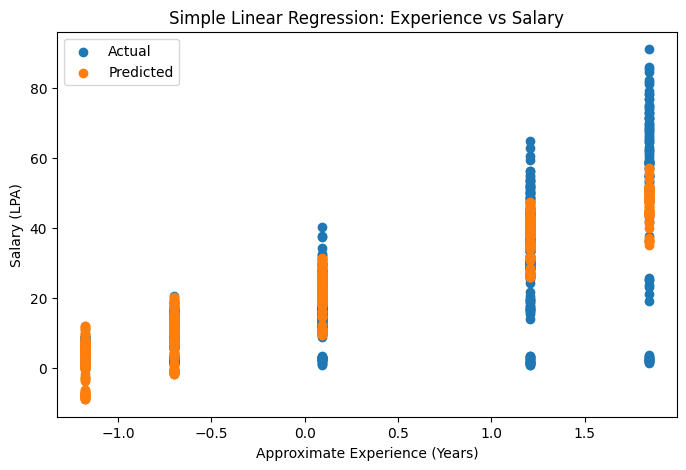

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

predictions = linear_model.predict(X_test)

print("Intercept:", linear_model.intercept_)
print("Coefficient:", linear_model.coef_[0])
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R-squared:", r2_score(y_test, predictions))

plt.figure(figsize=(8, 5))
plt.scatter(X_test["Experience_Years"], y_test, label="Actual")
plt.scatter(X_test["Experience_Years"], predictions, label="Predicted")
plt.xlabel("Approximate Experience (Years)")
plt.ylabel("Salary (LPA)")
plt.title("Simple Linear Regression: Experience vs Salary")
plt.legend()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Select features and target
features = [
    "Experience_Years",
    "Job_Title",
    "Company_Type",
    "Location_Tier",
    "Work_Mode",
    "Education_Required",
    "Company_Rating"
]

features = [col for col in features if col in df.columns]

model_df = df[features + ["Salary_LPA"]].copy()
model_df["Salary_LPA"] = pd.to_numeric(
    model_df["Salary_LPA"], errors="coerce"
)
model_df = model_df.dropna(subset=["Salary_LPA"])

X = model_df[features]
y = model_df["Salary_LPA"]

# Identify numerical and categorical features
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Handle missing numerical values
num_imputer = SimpleImputer(strategy="median")
X_numeric = pd.DataFrame(
    num_imputer.fit_transform(X[numeric_features]),
    columns=numeric_features,
    index=X.index
)

# Scale numerical features
scaler = StandardScaler()
X_numeric = pd.DataFrame(
    scaler.fit_transform(X_numeric),
    columns=numeric_features,
    index=X.index
)

# Handle missing categorical values
cat_imputer = SimpleImputer(strategy="most_frequent")
X_categorical = pd.DataFrame(
    cat_imputer.fit_transform(X[categorical_features]),
    columns=categorical_features,
    index=X.index
)

# Encode categorical features
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_categorical = pd.DataFrame(
    encoder.fit_transform(X_categorical),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X.index
)

# Combine processed features
X_processed = pd.concat([X_numeric, X_categorical], axis=1)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train Multiple Linear Regression
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

# Predict salary
predictions = multiple_model.predict(X_test)

# Evaluate model
print("Multiple Linear Regression")
print("Intercept:", multiple_model.intercept_)
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R-squared:", r2_score(y_test, predictions))

Multiple Linear Regression
Intercept: 19.25482944383767
MAE: 6.507676643283987
RMSE: 10.643226627833632
R-squared: 0.645797226331545


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

predictions = ridge_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R-squared:", r2_score(y_test, predictions))

MAE: 6.503753176841985
RMSE: 10.641824709889002
R-squared: 0.645890530841227


In [ ]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lasso_model = Lasso(alpha=0.1, max_iter=10000)
lasso_model.fit(X_train, y_train)

predictions = lasso_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R-squared:", r2_score(y_test, predictions))

MAE: 6.413955059436763
RMSE: 10.689169020120087
R-squared: 0.6427327337534645


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dt_model = DecisionTreeRegressor(max_depth=10, random_state=42)
dt_model.fit(X_train, y_train)

predictions = dt_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R-squared:", r2_score(y_test, predictions))

MAE: 5.161157304086614
RMSE: 10.343317321829991
R-squared: 0.6654777298371933


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

predictions = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R-squared:", r2_score(y_test, predictions))

MAE: 5.011816980127387
RMSE: 10.085896667894106
R-squared: 0.6819214616466301


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Train all models using the same features
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

lasso_model = Lasso(alpha=0.1, max_iter=10000)
lasso_model.fit(X_train, y_train)

dt_model = DecisionTreeRegressor(
    max_depth=10, random_state=42
)
dt_model.fit(X_train, y_train)

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

print("All five models trained successfully!")

All five models trained successfully!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R-squared": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

display(results_df.round(3))

,Model,MAE,RMSE,R-squared
0,Random Forest,5.012,10.086,0.682
1,Decision Tree,5.161,10.343,0.665
2,Ridge Regression,6.504,10.642,0.646
3,Linear Regression,6.508,10.643,0.646
4,Lasso Regression,6.414,10.689,0.643


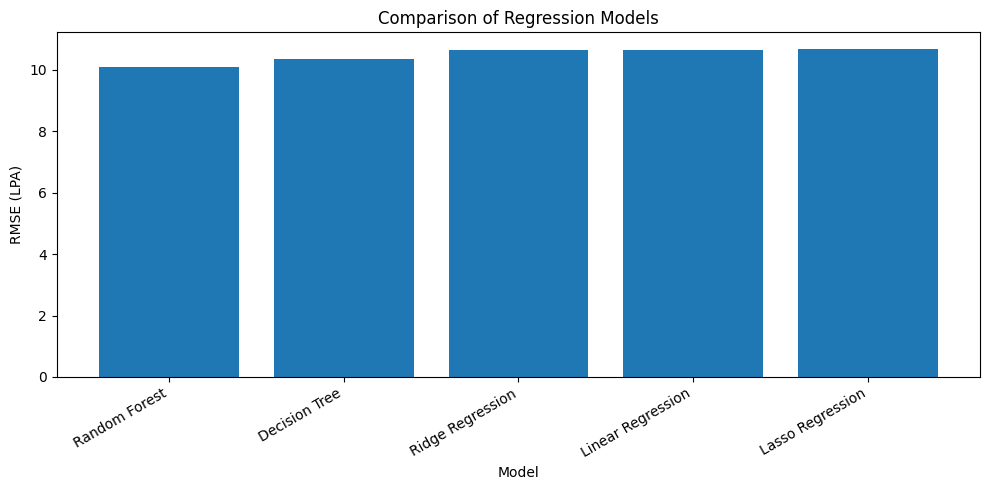

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("RMSE (LPA)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Display model comparison table
print("Regression Model Comparison:")
display(results_df.round(3))

# Identify the best model based on RMSE
best_model = results_df.iloc[0]

print("\nBest Performing Model:")
print("Model:", best_model["Model"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("R-squared:", best_model["R-squared"])

Regression Model Comparison:


,Model,MAE,RMSE,R-squared
0,Random Forest,5.012,10.086,0.682
1,Decision Tree,5.161,10.343,0.665
2,Ridge Regression,6.504,10.642,0.646
3,Linear Regression,6.508,10.643,0.646
4,Lasso Regression,6.414,10.689,0.643



Best Performing Model:
Model: Random Forest
MAE: 5.011816980127388
RMSE: 10.085896667894106
R-squared: 0.6819214616466301


In [ ]:
# Select the best model
best_model = best_model  # Use tuned Random Forest

# Generate predictions using the trained Random Forest model
rf_predictions = rf_model.predict(X_test)

print("Selected Model: Random Forest")
print("R² Score:", round(r2_score(y_test, rf_predictions), 3))
print("MAE:", round(mean_absolute_error(y_test, rf_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_predictions)), 3))

Selected Model: Random Forest
R² Score: 0.682
MAE: 5.012
RMSE: 10.086


In [ ]:
import pandas as pd
import numpy as np

# Create a sample job profile as float to prevent type conflicts
sample_job = pd.DataFrame(
    0.0, index=[0], columns=X_train.columns
)

# Enter example details
sample_job.loc[0, "Experience_Years"] = 3
sample_job.loc[0, "Company_Rating"] = 4.2

# Set categorical features using your encoded column names
sample_categories = {
    "Job_Title": "Data Analyst",
    "Company_Type": "MNC",
    "Location_Tier": "Tier 1",
    "Work_Mode": "Hybrid",
    "Education_Required": "Bachelor's"
}

for column, value in sample_categories.items():
    encoded_column = f"{column}_{value}"

    if encoded_column in sample_job.columns:
        sample_job.loc[0, encoded_column] = 1.0

# Predict salary using the actual rf_model instead of the best_model Series
predicted_salary = rf_model.predict(sample_job)[0]

print("SAMPLE JOB PROFILE")
print("------------------")
print("Job Title: Data Analyst")
print("Experience: 3 years")
print("Company Type: MNC")
print("Location: Tier 1")
print("Work Mode: Hybrid")
print("Company Rating: 4.2")

print("\nPredicted Annual Salary:", round(predicted_salary, 2), "LPA")
print("Approximate Annual Salary: ₹{:,.0f}".format(predicted_salary * 100000))

SAMPLE JOB PROFILE
------------------
Job Title: Data Analyst
Experience: 3 years
Company Type: MNC
Location: Tier 1
Work Mode: Hybrid
Company Rating: 4.2

Predicted Annual Salary: 19.48 LPA
Approximate Annual Salary: ₹1,947,912


In [ ]:
import joblib

joblib.dump(best_model, "techcareer_salary_model.pkl")
joblib.dump(list(X_train.columns), "techcareer_features.pkl")

print("Model tested and saved successfully!")


Model tested and saved successfully!


In [ ]:
import joblib

# Select the trained Random Forest model
best_model = rf_model

# Save the trained model
joblib.dump(best_model, "techcareer_salary_model.pkl")

# Save the feature names used during training
joblib.dump(list(X_train.columns), "techcareer_features.pkl")

print("Model saved successfully!")
print("Feature names saved successfully!")

Model saved successfully!
Feature names saved successfully!
